# Invisible Exposure: reference-free conformal auditing of open-map completeness

**Course project notebook (ADA).** This notebook walks through the whole pipeline: data, expectation model with conformal ranges, validation, the pre-registered equity audit, catch-up across Overture releases, and the release regression we found.

* Repository: https://github.com/GTX-Pradeep/invisible-exposure-open-map-equity
* The heavy data ingestion (Phase 1: streaming Overture releases from the cloud) is done by `scripts/01_count_overture.py` and takes about 30 minutes; set `RUN_INGEST = True` below to rerun it. Everything after it runs here in a few minutes.

**Problem statement.** Estimate, without a perfect reference map and with honest uncertainty, where Overture Maps is incomplete at census-tract level; convert the gaps into hidden heat, wildfire and drought exposure; and test, under a pre-registered plan, whether the gaps fall on socially vulnerable, rural and tribal communities and whether they close across releases.

**Design rule.** SVI, CVI, rurality, tribal and hazard variables never enter the model. They are joined only in the audit.

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
cfg = yaml.safe_load(open("config/config.yaml"))
RUN_INGEST = False   # True: re-stream Overture/USA Structures from the cloud (~30 min, needs network)
print("project root:", ROOT); print("regions:", cfg["regions"])

project root: /home/user/invisible-exposure-open-map-equity
regions: ['maricopa-az', 'northern-ca', 'eastern-ok', 'south-central-tx', 'eastern-wa']


## 1. Data ingestion (Phase 1)
Per-tract counts of Overture buildings (all and >= 450 sq ft) and places, with their upstream source, for three releases; USA Structures reference counts; Business Patterns establishments. The commands are below; with `RUN_INGEST = False` the cached outputs in `data/processed/` are used.

In [2]:
steps = ["bash scripts/fetch_challenge.sh", "bash scripts/fetch_inputs.sh",
         "python -c 'from coverage_risk.features import fetch_acs; fetch_acs()'",
         "python scripts/00b_usa_structures_counts.py", "python scripts/00c_poi_reference.py",
         "python scripts/01_count_overture.py --release r2026a", "python scripts/01_count_overture.py --release r2026b",
         "python scripts/01_count_overture.py --release r2023 --layer buildings", "python scripts/02_build_tract_table.py"]
if RUN_INGEST:
    for s in steps:
        print(">>", s); assert os.system(f"PYTHONPATH=src {s}") == 0
else:
    print("Using cached outputs. To rebuild, set RUN_INGEST = True. Steps:"); print("\n".join(steps))

Using cached outputs. To rebuild, set RUN_INGEST = True. Steps:
bash scripts/fetch_challenge.sh
bash scripts/fetch_inputs.sh
python -c 'from coverage_risk.features import fetch_acs; fetch_acs()'
python scripts/00b_usa_structures_counts.py
python scripts/00c_poi_reference.py
python scripts/01_count_overture.py --release r2026a
python scripts/01_count_overture.py --release r2026b
python scripts/01_count_overture.py --release r2023 --layer buildings
python scripts/02_build_tract_table.py


## 2. The tract table (Phase 2)

In [3]:
df = pd.read_parquet("data/processed/tracts_all.parquet")
strata = pd.read_parquet("data/processed/strata_audit.parquet")   # kept apart from the model table
print(df.shape, "| strata:", strata.shape)
df.groupby("region").agg(tracts=("GEOID", "size"), housing_units=("hu", "sum"),
    overture_buildings=("r2026a_bldg", "sum"), overture_places=("r2026a_poi", "sum"), usa_structures=("ref_bldg", "sum"))

(9794, 112) | strata: (9794, 39)


,tracts,housing_units,overture_buildings,overture_places,usa_structures
region,,,,,
eastern-ok,1192,1760700,2551694.0,207367.0,2248500.0
eastern-wa,415,710463,1081345.0,76490.0,798991.0
maricopa-az,1593,2918893,2908224.0,300044.0,2445963.0
northern-ca,591,1030699,1164723.0,116893.0,969606.0
south-central-tx,6003,10686216,11463800.0,1300281.0,9714665.0


### Feasibility gate: how complete is Overture against USA Structures?

log-scale correlation: 0.975
median ratio: 1.047   share of tracts below 80% of reference: 1.9%


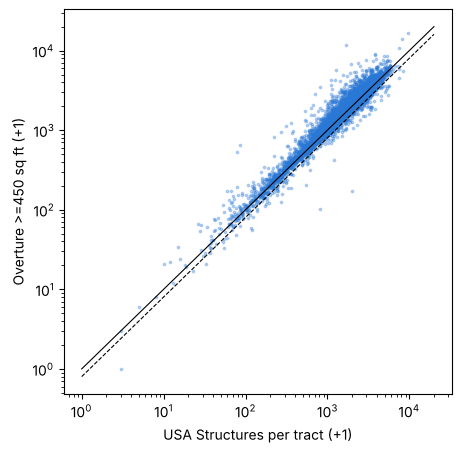

In [4]:
s = df[df.ref_bldg.notna()]
ratio = s.r2026a_bldg450 / s.ref_bldg
print(f"log-scale correlation: {np.corrcoef(np.log1p(s.r2026a_bldg450), np.log1p(s.ref_bldg))[0,1]:.3f}")
print(f"median ratio: {ratio.median():.3f}   share of tracts below 80% of reference: {(ratio < 0.8).mean():.1%}")
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(s.ref_bldg + 1, s.r2026a_bldg450 + 1, s=3, alpha=.3, color="#2a78d6")
lim = [1, 2e4]; ax.plot(lim, lim, "k-", lw=.8); ax.plot(lim, [0.8 * x for x in lim], "k--", lw=.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("USA Structures per tract (+1)"); ax.set_ylabel("Overture >=450 sq ft (+1)")
plt.show()

## 3. Expectation model with conformal ranges (Phase 3)
LightGBM quantile regression on log counts, structural covariates only, cross-fitted on 50 km spatial blocks; conformalized quantile regression (CQR) gives a 90% range per tract. A tract is **flagged** when the map falls below the lower bound. The leakage guard refuses audit columns:

In [5]:
from coverage_risk.model import STRUCTURAL, crossfit_cqr, make_folds, assert_no_leakage
try:
    assert_no_leakage(STRUCTURAL + ["svi_overall"])
except ValueError as e:
    print("guard works ->", e)
print(len(STRUCTURAL), "structural features, e.g.", STRUCTURAL[:8])

guard works -> audit/outcome columns refused as model inputs: ['svi_overall']
66 structural features, e.g. ['hu', 'pop', 'households', 'gq_pop', 'vacant_share', 'u1_det', 'u1_att', 'u2']


In [6]:
mc = cfg["model"]
folds = make_folds(df, "spatial", k=10, seed=mc["seed"], km=mc["spatial_block_km"])
res = {}
for layer, target in [("bldg", "r2026a_bldg450"), ("poi", "r2026a_poi")]:
    res[layer] = crossfit_cqr(df, target, STRUCTURAL, folds, alpha=mc["alpha"], params=mc["lgbm"], seed=mc["seed"])
    o = res[layer]; r2 = 1 - ((o.y_log - o.q_med)**2).sum() / ((o.y_log - o.y_log.mean())**2).sum()
    print(f"{layer}: coverage {o.covered.mean():.3f} | flag rate {o.flag.mean():.3f} | R2(log) {r2:.3f} | flagged {o.flag.sum()}")

bldg: coverage 0.900 | flag rate 0.052 | R2(log) 0.926 | flagged 510


poi: coverage 0.900 | flag rate 0.054 | R2(log) 0.824 | flagged 529


## 4. Validation (Phase 4)

In [7]:
from coverage_risk.validation import flag_skill, deletion_test
o = res["bldg"]; truth = (df.r2026a_bldg450 / df.ref_bldg < 0.8).values; ok = df.ref_bldg.notna().values
print("Flags vs USA Structures gaps:", {k: round(v, 3) for k, v in flag_skill(o.flag.values[ok], o.deficit_z.values[ok], truth[ok]).items()})
print(deletion_test(o, seed=mc["seed"]).to_string(index=False))

Flags vs USA Structures gaps: {'n': 9793, 'prevalence': 0.019, 'n_flag': 510, 'n_true': 182, 'precision': 0.094, 'recall': 0.264, 'f1': 0.139, 'lift': 5.064, 'auc': 0.685, 'pr_auc': 0.099}
 removed_share  detection_rate
           0.1          0.1060
           0.2          0.3695
           0.3          0.6635
           0.5          0.9555
           0.7          0.9955
           0.9          0.9985


In [8]:
print("CV schemes x calibration (from scripts/04_validation.py):")
pd.read_csv("outputs/tables/cv_schemes.csv")[["layer","scheme","calibration","coverage","flag_rate","r2_log","cov_region_min","cov_region_max"]].round(3)

CV schemes x calibration (from scripts/04_validation.py):


,layer,scheme,calibration,coverage,flag_rate,r2_log,cov_region_min,cov_region_max
0,bldg,random,global,0.900,0.052,0.930,0.889,0.931
1,bldg,random,mondrian-region,0.900,0.052,0.930,0.898,0.901
2,bldg,spatial,global,0.900,0.052,0.926,0.889,0.932
3,bldg,spatial,mondrian-region,0.900,0.052,0.926,0.889,0.902
4,bldg,region,global,0.846,0.089,0.904,0.781,0.968
5,bldg,region,mondrian-region,0.846,0.089,0.904,0.781,0.968
6,poi,random,global,0.900,0.055,0.830,0.870,0.924
7,poi,random,mondrian-region,0.901,0.055,0.830,0.899,0.902
8,poi,spatial,global,0.900,0.054,0.824,0.853,0.934
9,poi,spatial,mondrian-region,0.899,0.054,0.824,0.897,0.901


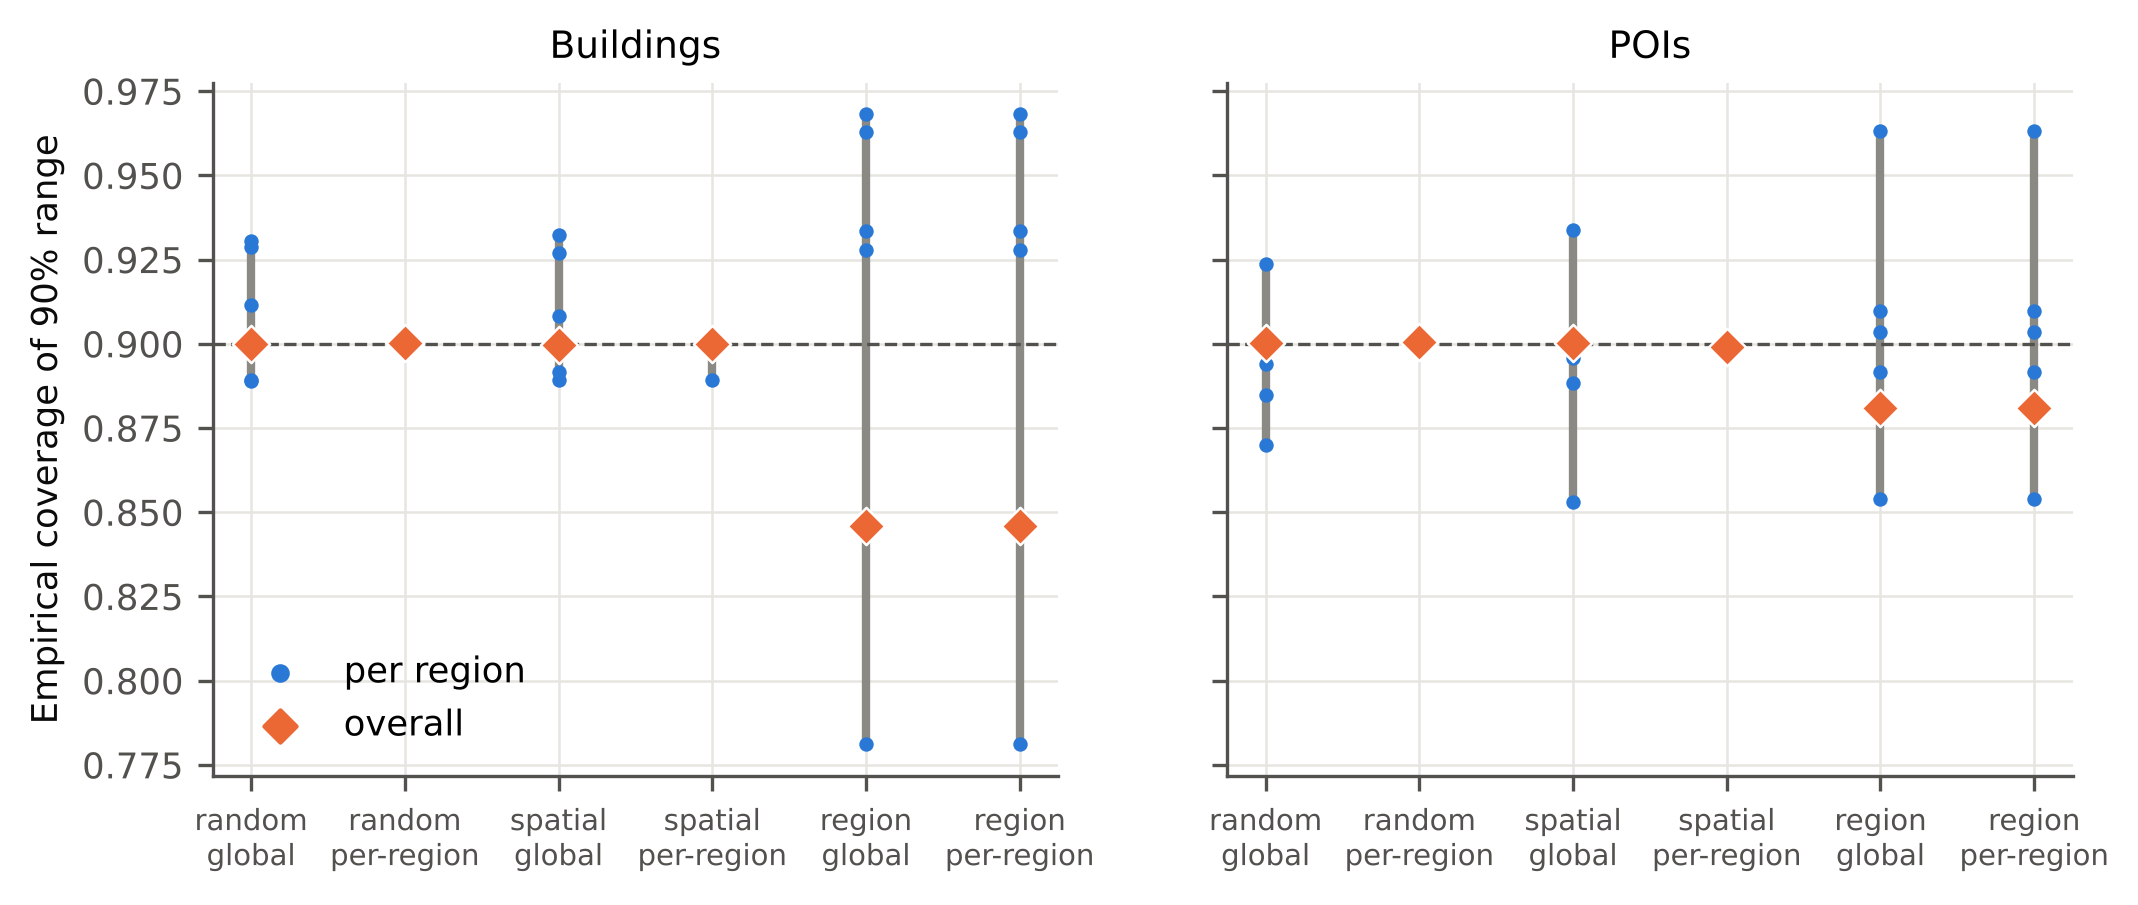

In [9]:
display(Image('outputs/figures/fig3_coverage_schemes.png', width=800))

## 5. Pre-registered equity audit (Phases 5-6)
Hypotheses were frozen in `docs/preregistration.md` before this step. Strata are joined here for the first time.

In [10]:
from coverage_risk.audit import define_groups, flag_contrast, exposure_ratio, bh
d = df.merge(define_groups(strata), on="GEOID").merge(strata.drop(columns="region"), on="GEOID")
for layer in ["bldg", "poi"]:
    for c in ["flag", "shortfall_lower", "deficit_z"]:
        d[f"{layer}_{c}"] = res[layer][c].values
rows = []
for layer in ["bldg", "poi"]:
    for g in ["svi", "cvi", "rural", "tribal"]:
        r = flag_contrast(d, f"{layer}_flag", g, n_boot=1000, seed=mc["seed"]); rows.append({"layer": layer, **r})
for hz, col in {"heat": "epht_heat_days_summer", "wildfire": "usfs_BP_mean", "drought": "usdm_summer_dsci"}.items():
    for g in ["svi", "rural", "tribal"]:
        rows.append({"layer": "bldg", "hazard": hz, **exposure_ratio(d, col, g, n_boot=1000, seed=mc["seed"])})
a = pd.DataFrame(rows)
a["reject_bh"], a["p_bh"] = bh(a.p)
a[["layer","hazard","group","contrast","rate_hi","rate_lo","risk_diff","adj_odds_ratio","rate_ratio","ci_lo","ci_hi","p","p_bh","reject_bh"]].round(4)

/home/user/.venv/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,layer,hazard,group,contrast,rate_hi,rate_lo,risk_diff,adj_odds_ratio,rate_ratio,ci_lo,ci_hi,p,p_bh,reject_bh
0,bldg,NaN,svi,Q4 vs Q1,0.0598,0.0505,0.0093,1.1913,NaN,NaN,NaN,0.2779,0.5250,False
1,bldg,NaN,cvi,top vs bottom,0.0633,0.0453,0.0180,1.2517,NaN,NaN,NaN,0.2103,0.4632,False
2,bldg,NaN,rural,rural vs urban,0.0503,0.0524,-0.0022,1.0613,NaN,NaN,NaN,0.7649,0.8181,False
3,bldg,NaN,tribal,tribal vs non-tribal,0.0423,0.0530,-0.0107,1.1226,NaN,NaN,NaN,0.8503,0.8503,False
4,poi,NaN,svi,Q4 vs Q1,0.0381,0.0889,-0.0509,0.4093,NaN,NaN,NaN,0.0000,0.0000,True
5,poi,NaN,cvi,top vs bottom,0.0404,0.0752,-0.0347,0.5772,NaN,NaN,NaN,0.0004,0.0032,True
6,poi,NaN,rural,rural vs urban,0.0367,0.0576,-0.0210,0.5624,NaN,NaN,NaN,0.0006,0.0036,True
7,poi,NaN,tribal,tribal vs non-tribal,0.0492,0.0545,-0.0053,0.8354,NaN,NaN,NaN,0.5301,0.6437,False
8,bldg,epht_heat_days_summer,svi,Q4 vs Q1,NaN,NaN,NaN,NaN,1.3668,0.7374,3.4614,0.3140,0.5338,False
9,bldg,epht_heat_days_summer,rural,rural vs urban,NaN,NaN,NaN,NaN,0.6033,0.1894,2.5720,0.5180,0.6437,False


In [11]:
print("Full confirmatory family incl. H3 (scripts/06b_fdr.py):")
pd.read_csv("outputs/tables/confirmatory_fdr.csv")[["hyp","layer","hazard_name","group","risk_diff","adj_odds_ratio","rate_ratio","adj_diff","p","p_bh","reject_bh"]].round(4)

Full confirmatory family incl. H3 (scripts/06b_fdr.py):


,hyp,layer,hazard_name,group,risk_diff,adj_odds_ratio,rate_ratio,adj_diff,p,p_bh,reject_bh
0,H1,bldg,NaN,svi,0.0093,1.1913,NaN,NaN,0.2779,0.5345,False
1,H1,bldg,NaN,cvi,0.0180,1.2517,NaN,NaN,0.2103,0.4382,False
2,H2,bldg,NaN,rural,-0.0022,1.0613,NaN,NaN,0.7649,0.8219,False
3,H2,bldg,NaN,tribal,-0.0107,1.1226,NaN,NaN,0.8503,0.8503,False
4,H1,poi,NaN,svi,-0.0509,0.4093,NaN,NaN,0.0000,0.0000,True
5,H1,poi,NaN,cvi,-0.0347,0.5772,NaN,NaN,0.0004,0.0026,True
6,H2,poi,NaN,rural,-0.0210,0.5624,NaN,NaN,0.0006,0.0026,True
7,H2,poi,NaN,tribal,-0.0053,0.8354,NaN,NaN,0.5301,0.6626,False
8,H5,bldg,heat,svi,NaN,NaN,1.3668,NaN,0.3130,0.5589,False
9,H5,bldg,heat,rural,NaN,NaN,0.6033,NaN,0.5080,0.6626,False


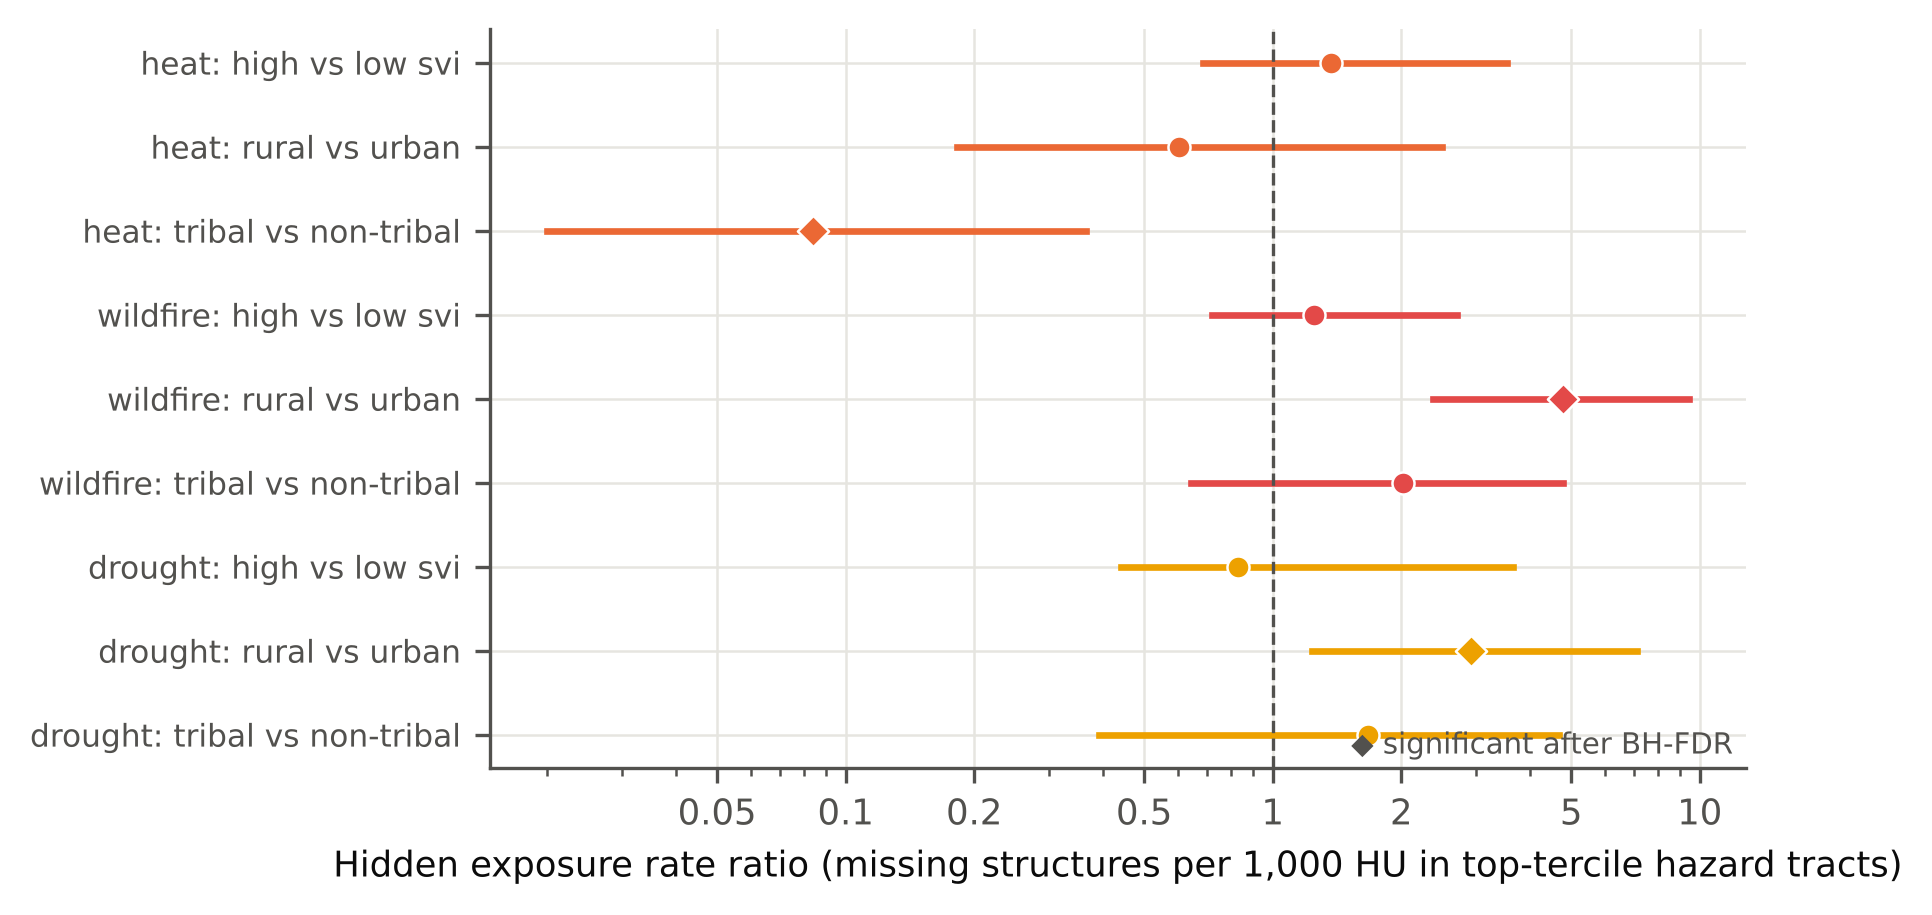

In [12]:
display(Image('outputs/figures/fig7_hidden_exposure.png', width=650))

## 6. Catch-up across releases (Phase 7, H3) and the release regression

In [13]:
snap = pd.read_csv("outputs/tables/h3_snapshots.csv")
snap[["snapshot","buildings","buildings450","share_tracts_lt80","lt80_rural_rural","lt80_rural_urban","lt80_tribal_tribal","lt80_svi_Q4"]].round(4)

,snapshot,buildings,buildings450,share_tracts_lt80,lt80_rural_rural,lt80_rural_urban,lt80_tribal_tribal,lt80_svi_Q4
0,r2023,17343068.0,16235217.0,0.0701,0.1570,0.0520,0.1362,0.0761
1,r2026a,19169786.0,17584880.0,0.0185,0.0468,0.0126,0.0435,0.0175
2,r2026b,19046115.0,17459130.0,0.0374,0.0421,0.0364,0.0423,0.0529


In [14]:
c = pd.read_parquet("data/processed/catchup_frame.parquet")
loss = (c.r2026a_bldg450 - c.r2026b_bldg450) / c.r2026a_bldg450.clip(lower=1)
reg = loss > 0.20
print(f"tracts losing >20% of buildings Aug->Oct 2026: {reg.sum()} (Bexar County: {(reg & (c.county=='48029')).sum()})")
print(f"buildings lost: {(c.r2026a_bldg450 - c.r2026b_bldg450)[reg].sum():,.0f}; residents: {c.loc[reg,'pop'].sum():,.0f}")
print(f"flag rate in those tracts: Aug {c.loc[reg,'flag_r2026a'].mean():.1%} -> Oct {c.loc[reg,'flag_r2026b'].mean():.1%} (no reference used)")

tracts losing >20% of buildings Aug->Oct 2026: 186 (Bexar County: 181)
buildings lost: 179,047; residents: 888,819
flag rate in those tracts: Aug 2.7% -> Oct 82.3% (no reference used)


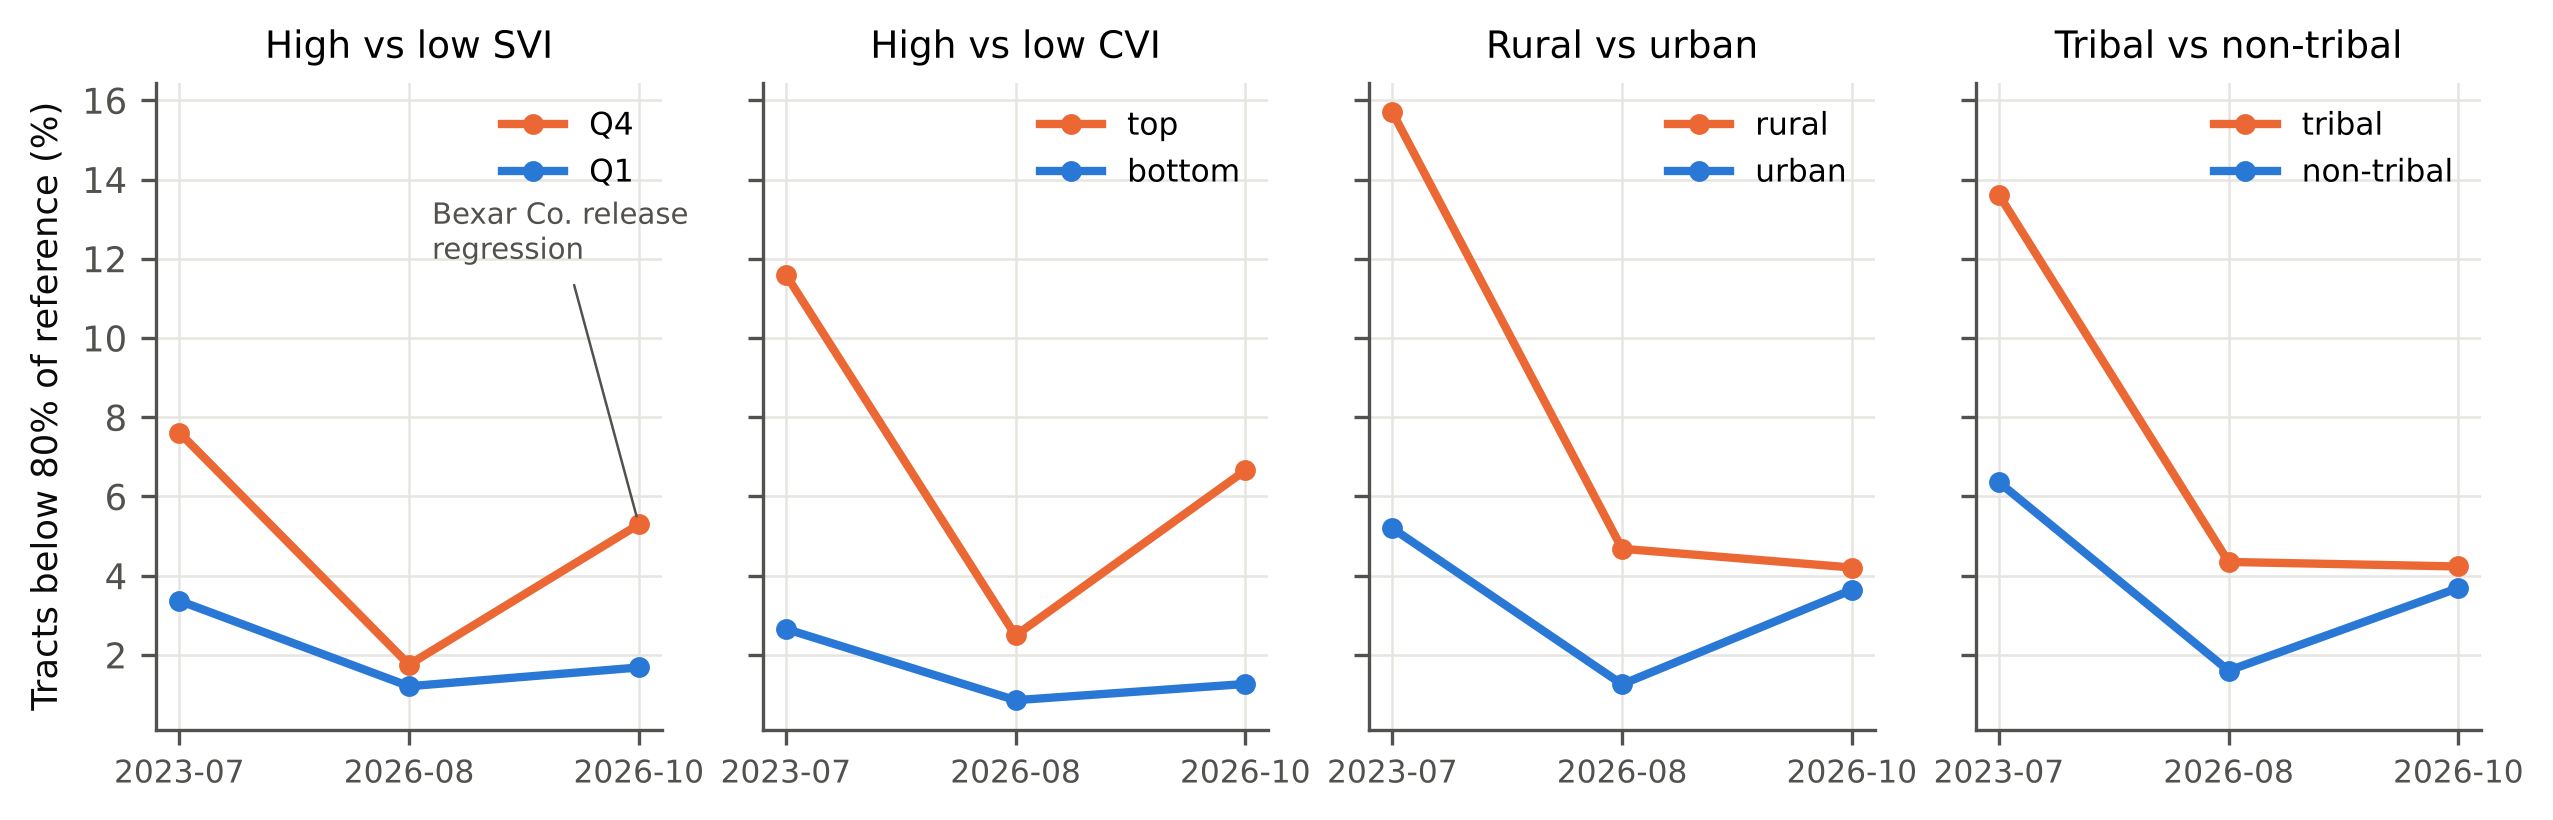

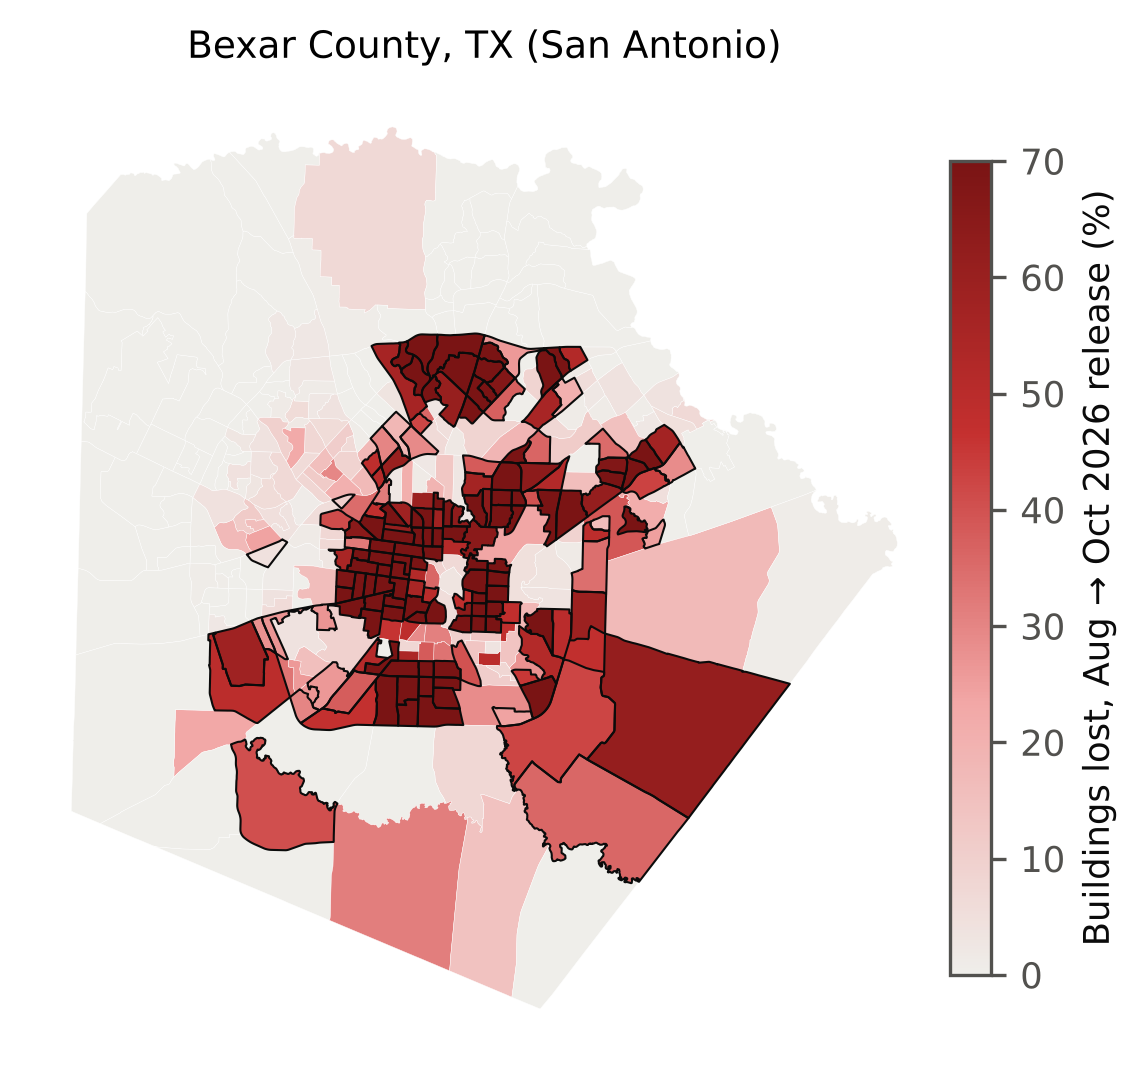

In [15]:
display(Image('outputs/figures/fig6_catchup.png', width=900)); display(Image('outputs/figures/fig8_bexar_regression.png', width=450))

## 7. Why tract flags miss group-wide gaps (exploratory)

{'E2_absorbed_share_svi': 1.103, 'E2_absorbed_share_cvi': 0.957, 'E2_absorbed_share_rural': 0.799, 'E2_absorbed_share_tribal': 0.638, 'E2_resid_sd_log_maptrained': 0.194, 'E2_resid_sd_log_anchored': 0.211, 'E2_gap_threshold_log': 0.223}


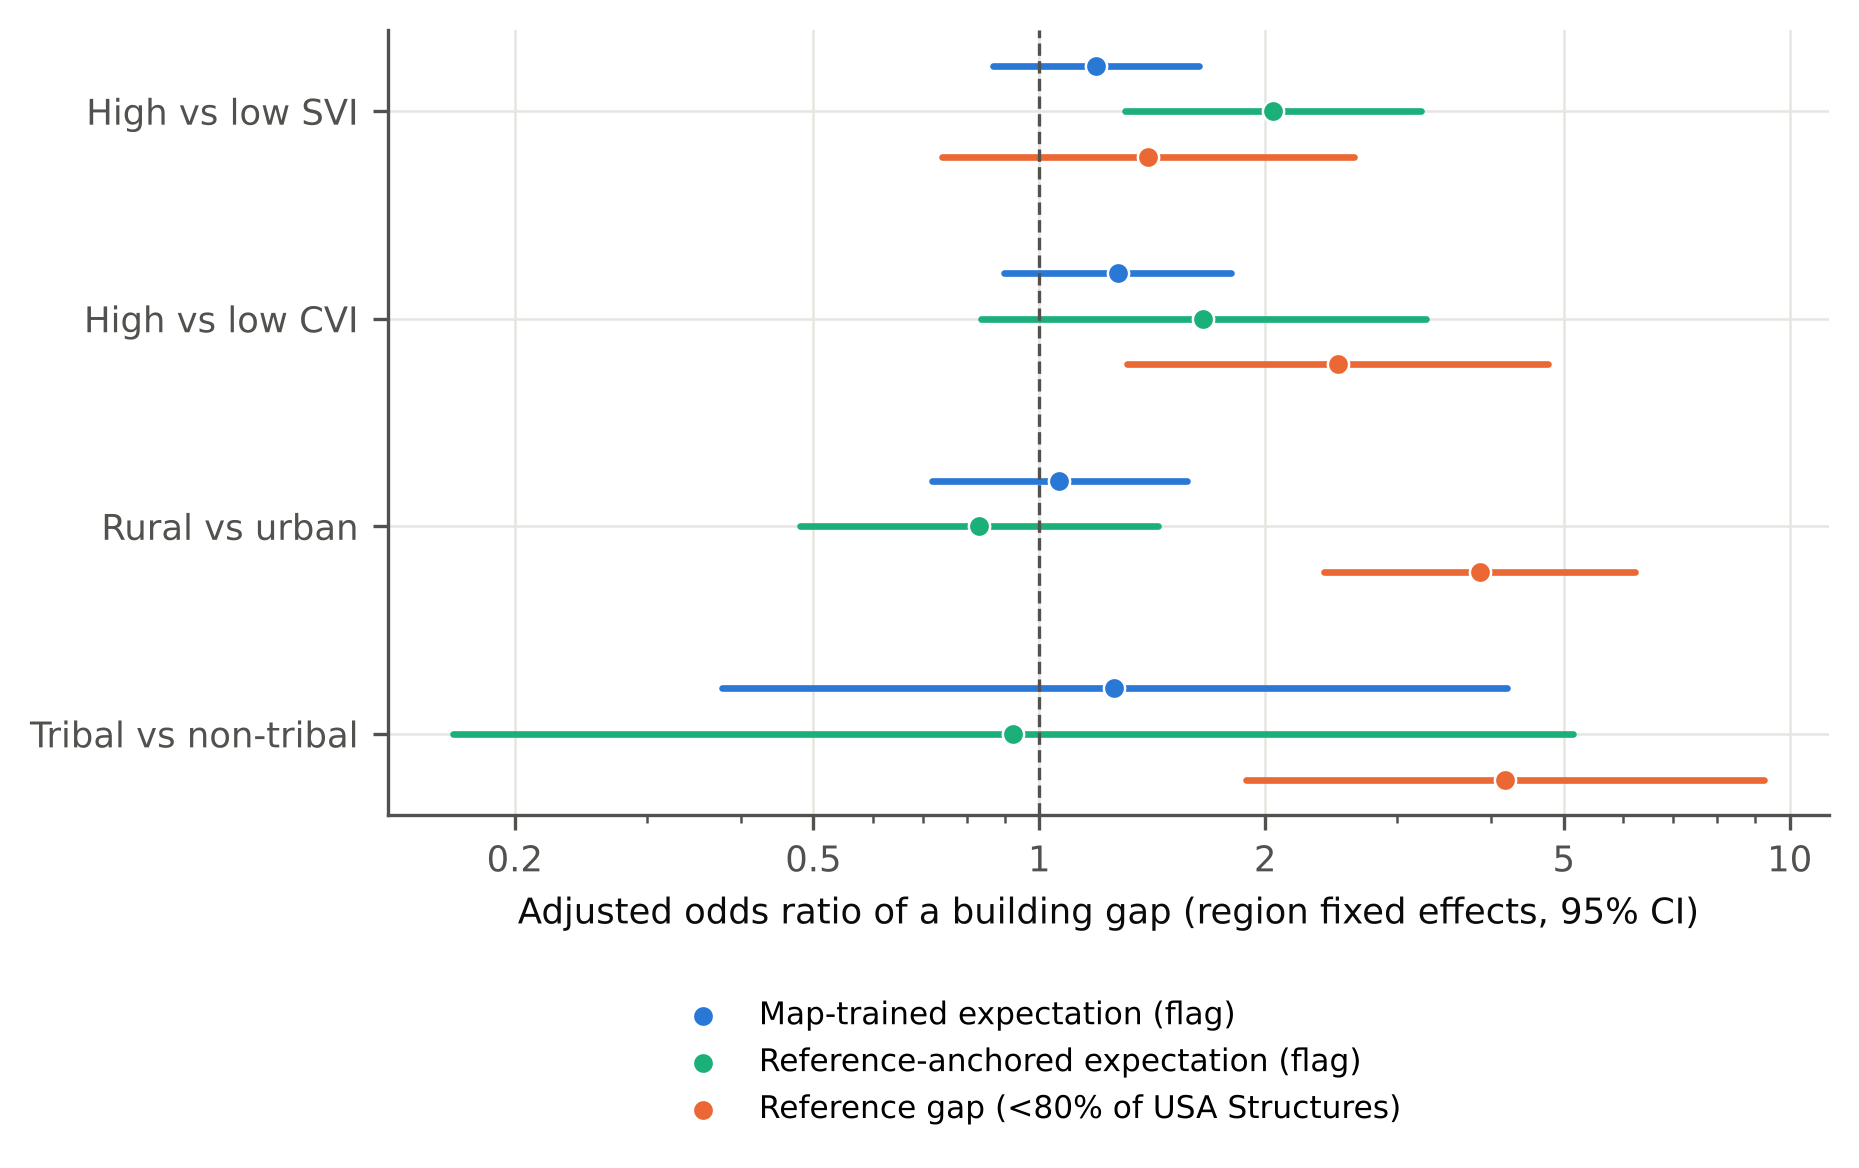

In [16]:
e = json.load(open("outputs/tables/exploratory.json"))
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in e.items() if k.startswith("E2_absorbed") or k.startswith("E2_resid") or k == "E2_gap_threshold_log"})
display(Image('outputs/figures/fig5_two_lenses.png', width=650))

## 8. Conclusions
* Conformal ranges are calibrated (90% coverage) under spatial cross-fitting, but not when transferred to a new region without local calibration.
* Overture buildings are close to complete here; rural and tribal gaps closed faster from 2023 to 2026.
* A silent 2026 release regression removed about 179,000 buildings from San Antonio tracts, mostly high-vulnerability ones, and the reference-free model detected it.
* Hidden wildfire exposure is concentrated in rural tracts.
* Tract-level flags cannot see modest, group-wide gaps; equity audits need reference comparisons aggregated by group.

Full details: `paper/main.pdf`, `deliverables/IEEE_Report.pdf`, `deliverables/Invisible_Exposure_Project_Documentation.docx`.